# НП Дадья: ноутбуки дослідження

Кожен ноутбук повторює блок сторінки `web/science/` і використовує той самий код: задачі `ds/tasks/`, підсумки `data/processed/experiments_summary.json`, спільні функції `ds/report.py`.

| Гілка | Питання | Тип |
|---|---|---|
| [FD](01_FD.ipynb) | Що саме згоріло у 2023 році і скільки? | виміряно |
| [FM](02_FM.ipynb) | Які теплові точки з двох супутників це одна пожежа? | виміряно |
| [FG day](03_FG_day.ipynb) | Чи можна за погодою заздалегідь виділити дні з пожежами? | виміряно |
| [FG risk](04_FG_risk.ipynb) | Які ділянки парку згорять наступними? | виміряно |
| [FG spread](05_FG_spread.ipynb) | Куди піде фронт пожежі за добу? | виміряно |
| [AR](06_AR.ipynb) | Де пожежі повторюються на тих самих місцях? | виміряно |
| [LD](07_LD.ipynb) | Чи видно рубку на знімках Sentinel-2, коли рубок мало? | виміряно |
| [LM](08_LM.ipynb) | Чи точніший збіг Sentinel-2 і NASA OPERA, ніж одне джерело? | виміряно |
| [LG](09_LG.ipynb) | Де рубатимуть наступного року? | виміряно |
| [SD](10_SD.ipynb) | Чи видно машини згори і за якої роздільності? | виміряно |
| [CD](11_CD.ipynb) | Наскільки точно готові моделі бачать дим і вогонь на фото? | виміряно |
| [TP](12_TP.ipynb) | Де поставити вежі, щоб побачити найбільше майбутніх пожеж? | сценарний аналіз |
| [CG](13_CG.ipynb) | Де на мапі дим, якщо камера бачить лише напрямок? | сценарний аналіз |
| [CP](14_CP.ipynb) | Через які місця на дорогах проходить під'їзд до рубок? | сценарний аналіз |
| [XM](15_XM.ipynb) | Як звести сигнали з різних джерел в одну подію? | симуляція |
| [AS](16_AS.ipynb) | Які зони інтересу є в парку, якого типу, з якими рисами в часі й просторі і з яких джерел? | симуляція |
| [Датасети](90_datasets.ipynb) | EDA кожного датасету | |

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Усі задачі: обраний підхід на тесті

,гілка,тип,обрано
0,FD,виміряно,s2_dnbr
1,FM,виміряно,st_2.0km_5d
2,FG_day,виміряно,lightgbm
3,FG_risk,виміряно,f22_lgbm_all
4,FG_spread,виміряно,lightgbm_lag
5,AR,виміряно,—
6,LD,виміряно,lightgbm
7,LM,виміряно,—
8,LG,виміряно,логрег
9,SD,виміряно,—


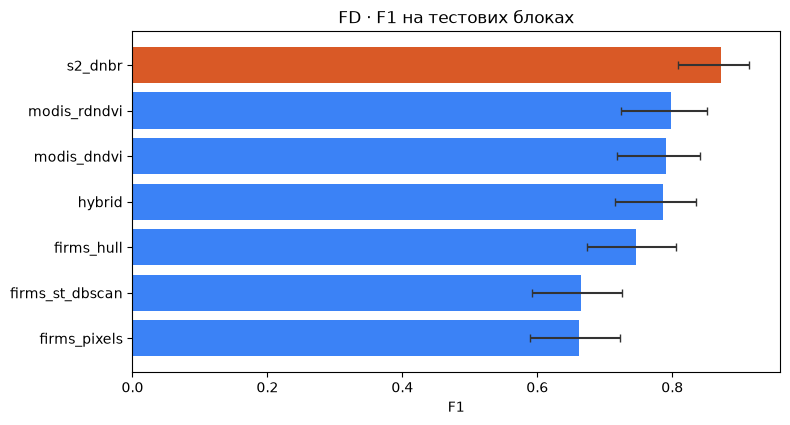

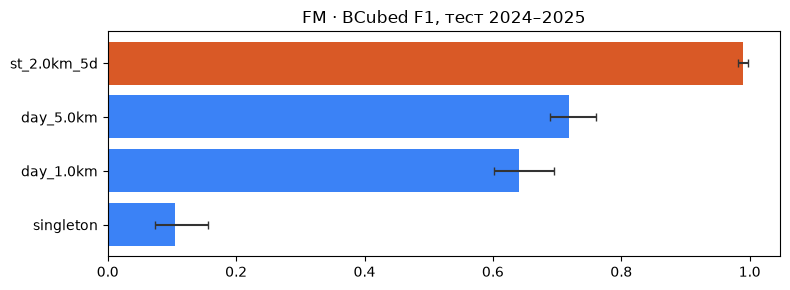

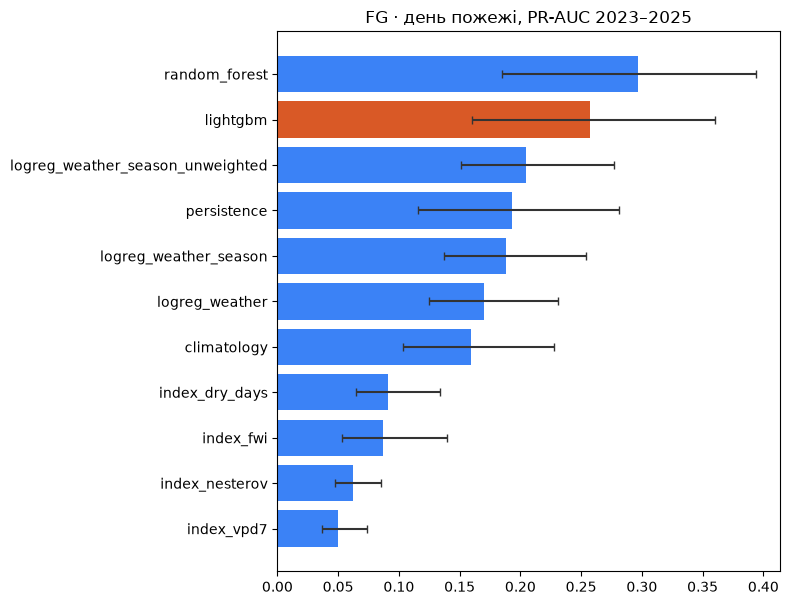

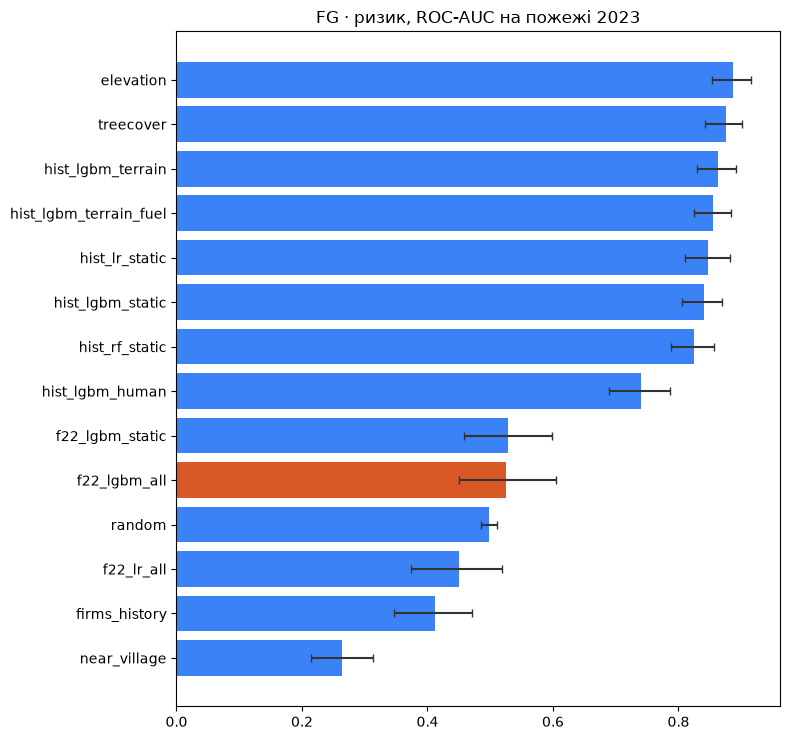

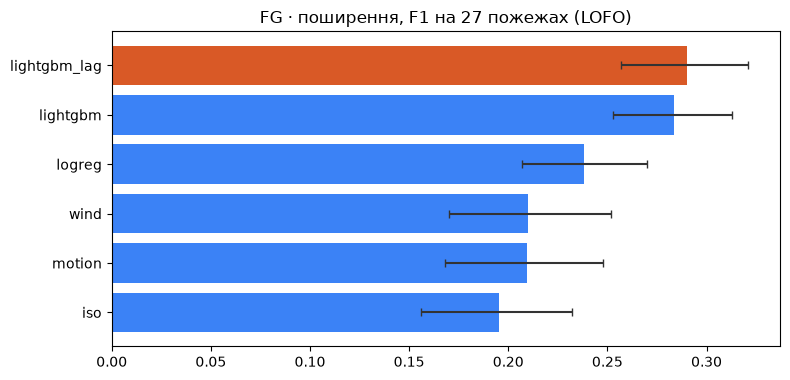

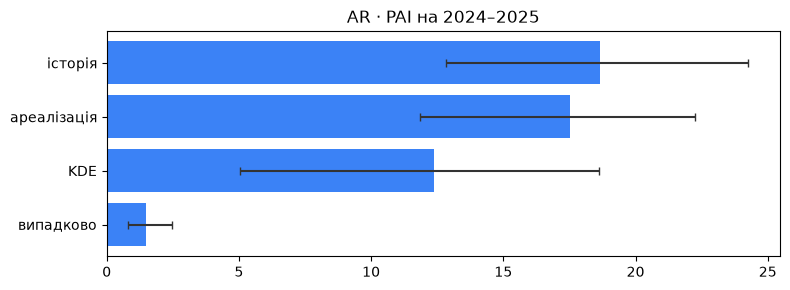

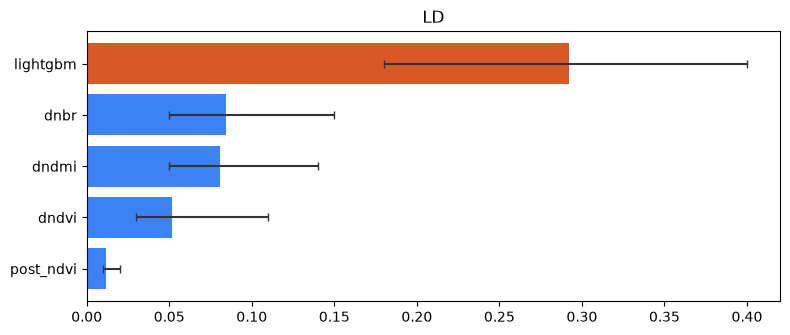

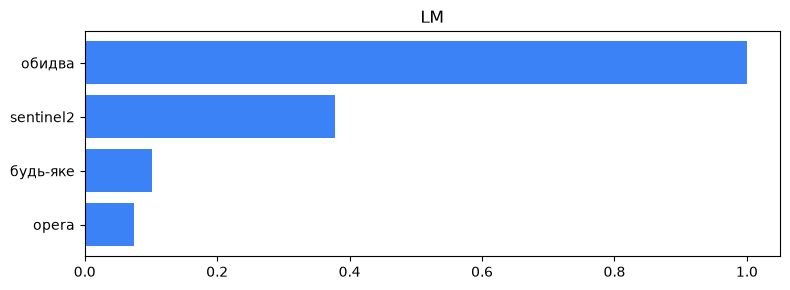

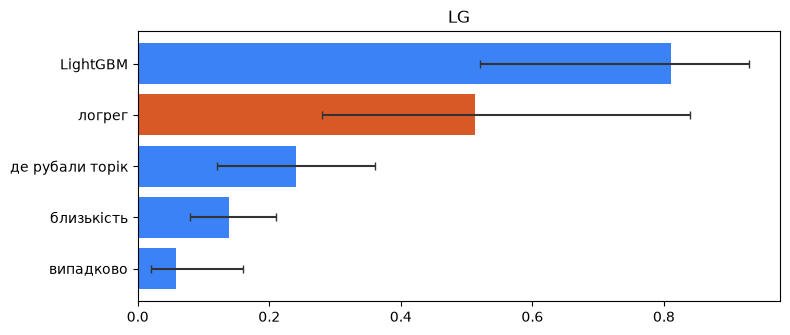

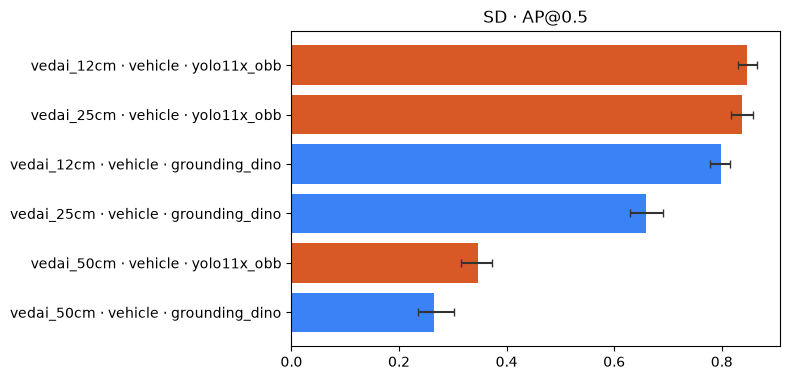

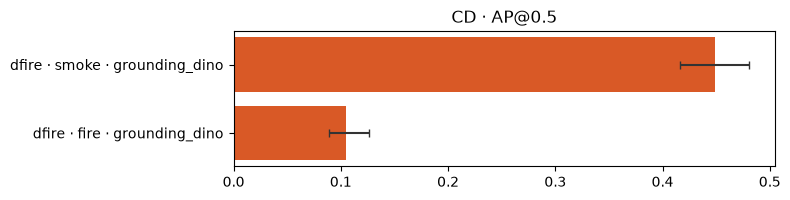

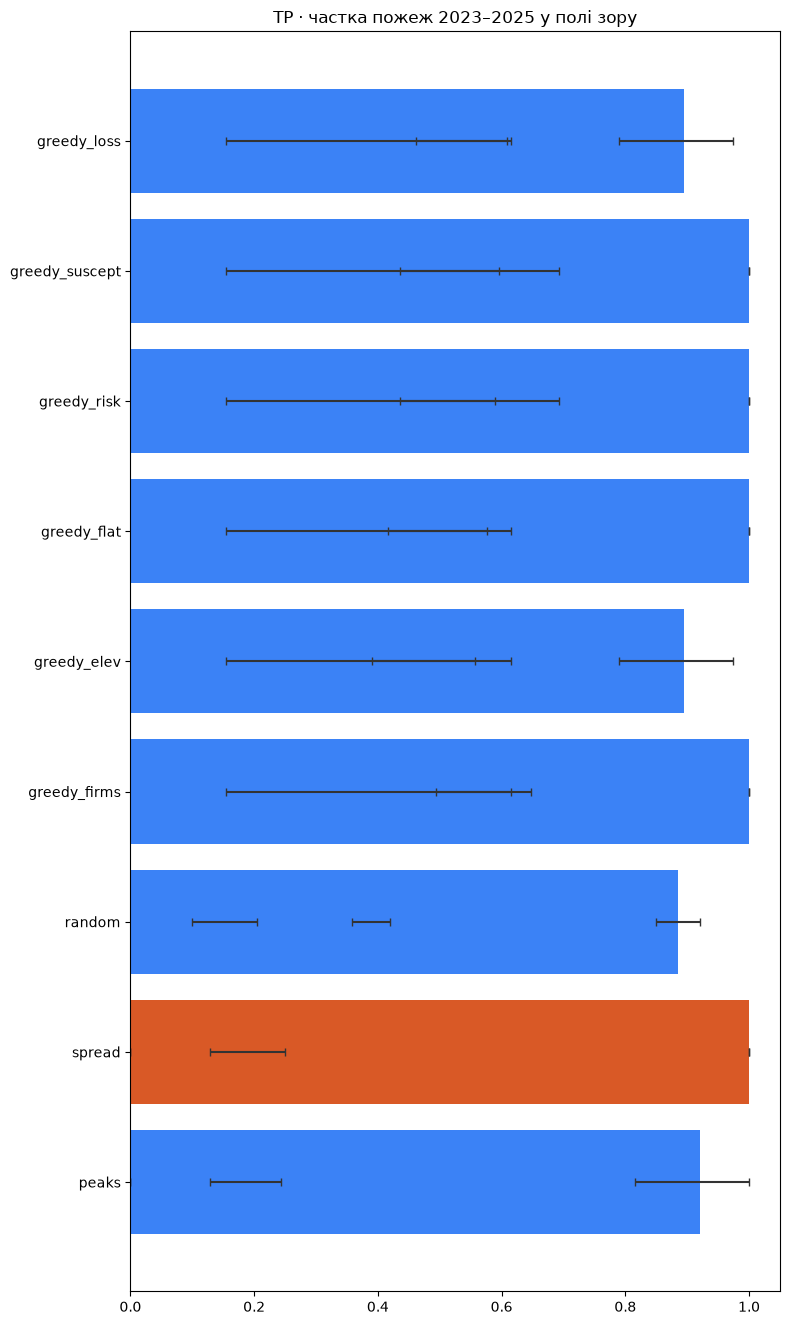

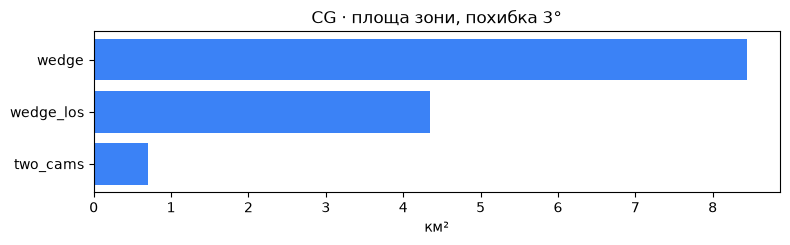

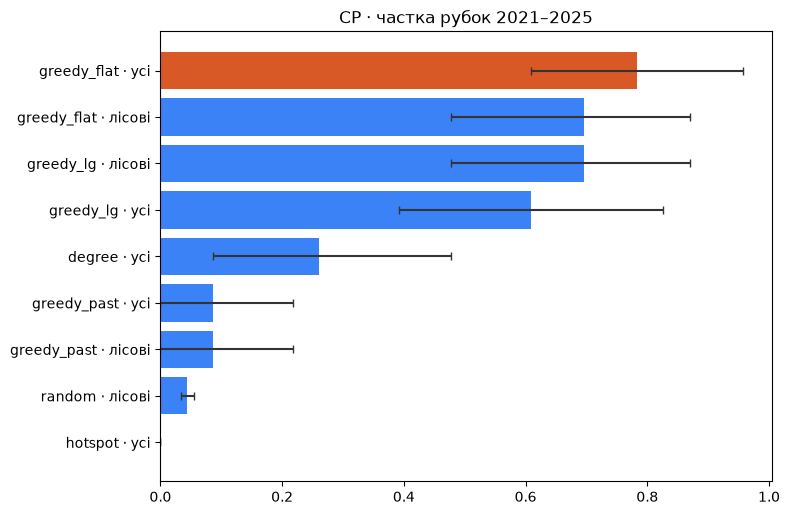

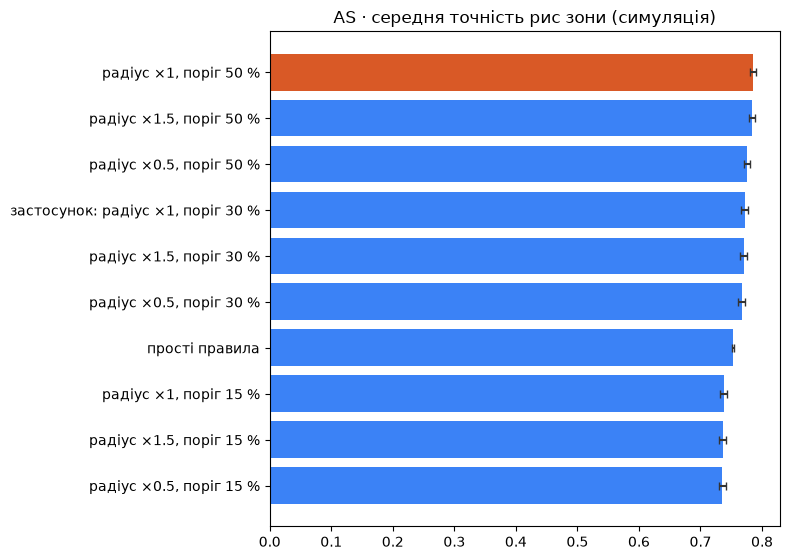

In [2]:
rows = []
for c, b in report.BRANCHES.items():
    t, _ = report.show(c)
    ch = t[t['champion'].fillna(False).astype(bool)] if 'champion' in t else t.head(0)
    rows.append(dict(гілка=c, тип=report.KIND[b['kind']], обрано=(ch.iloc[0, 0] if len(ch) else '—')))
pd.DataFrame(rows)